In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import cv2

# Extracted data Directory
# input_data_dir = "/media/yshen47/674eaf4c-ac33-42a8-9a4c-cace68d8cccd/home/gem/demo_ws/src/HIL_Research/src/hil/data/cone_il_extracted/cone_first_pass_2022-12-15-09-07-15"
input_data_dir = "/media/bhargav/03E7-EC27/cone_bags_extracted/cone2_2022-12-12-16-30-37"
# topic_save_paths = [
#             "pc", 
#             "gps.csv", "accel.csv", "brake.csv", "steer.csv", "speed.csv",
#             "depth", "img_l", "img_r"
#         ]
# Load the paths to each csv/data directory
imgl_format_path = os.path.join(input_data_dir, "img_l", "{}.png")
depth_format_path = os.path.join(input_data_dir, "depth", "{}.npy")

gps_path = os.path.join(input_data_dir, "gps.csv")
brake_path = os.path.join(input_data_dir, "brake.csv")
accel_path = os.path.join(input_data_dir, "accel.csv")
steer_path = os.path.join(input_data_dir, "steer.csv")
speed_path = os.path.join(input_data_dir, "speed.csv")

# Holds the timestamps/sequence numbers for synced sets of img/gps/pacmod data, 
# Each row in this csv is one synced datapoint 
sync_csv_path = os.path.join(input_data_dir, "synced.csv")
df = pd.read_csv(sync_csv_path)
df

,image_stamp,gps_stamp,depth_stamp,accel_seqnum,brake_seqnum,steer_seqnum,speed_seqnum
0,1670884239387086949,1670884239395665455,1670884239387086949,4175,4175,62037,62037
1,1670884239420171949,1670884239415919013,1670884239420171949,4176,4176,62038,62038
2,1670884239453769949,1670884239456418771,1670884239453769949,4177,4177,62039,62039
3,1670884239486955949,1670884239496089803,1670884239486955949,4179,4179,62040,62040
4,1670884239520203949,1670884239516039419,1670884239520203949,4180,4180,62041,62041
...,...,...,...,...,...,...,...
260,1670884250788121949,1670884250795191481,1670884250788121949,4359,4359,62378,62378
261,1670884250820821949,1670884250815339356,1670884250820821949,4360,4360,62379,62380
262,1670884250854445949,1670884250855874859,1670884250854445949,4361,4361,62381,62381
263,1670884250920749949,1670884250916368465,1670884250920749949,4362,4362,62382,62383


For all Pacmod data(brake, acceleratation, steer, speed), the `synced.csv` file contains the relevant sequence number for the respective pacmod data csv to pull for each data point.

In [3]:
df_brake = pd.read_csv(brake_path)
# print(df_brake.head())
brake_vals = []
for i in df["brake_seqnum"]:
    # match sequence number from synced.csv to a row in brake.csv and append the brake command value in the row(field.f64_cmd)
    brake_vals.append(df_brake[df_brake["field.header.seq"]==i]["field.f64_cmd"].item())
brake_vals = np.array(brake_vals)

In [4]:
df_accel = pd.read_csv(accel_path)
accel_vals = []
for i in df["accel_seqnum"]:
    accel_vals.append(df_accel[df_accel["field.header.seq"]==i]["field.f64_cmd"].item())
accel_vals = np.array(accel_vals)

In [5]:
df_steer = pd.read_csv(steer_path)
steer_vals = []
for i in df["steer_seqnum"]:
    steer_vals.append(df_steer[df_steer["field.header.seq"]==i]["field.manual_input"].item())
steer_vals = np.array(steer_vals)

In [6]:
df_speed = pd.read_csv(speed_path)
speed_vals = []
for i in df["speed_seqnum"]:
    speed_vals.append(df_speed[df_speed["field.header.seq"]==i]["field.vehicle_speed"].item())
speed_vals = np.array(speed_vals)

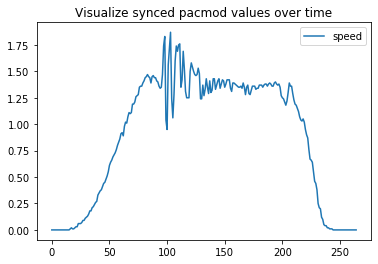

In [7]:
# plt.plot(brake_vals, label="brake")
# plt.plot(accel_vals, label="accel")
plt.plot(speed_vals, label="speed")
# plt.plot(steer_vals, label="steer")
plt.title("Visualize synced pacmod values over time")
plt.legend()
plt.show()

In [8]:
df_gps = pd.read_csv(gps_path)
gps_vals = []
gps_speed = []
for i in df["gps_stamp"]:
    matched_row = df_gps[df_gps["field.header.stamp"]==i]
    fields = ["field.latitude", "field.longitude", "field.height", "field.roll", "field.pitch", "field.azimuth", "field.header.stamp"]
    east_vel = matched_row["field.east_velocity"].item()
    north_vel = matched_row["field.north_velocity"].item()
    gps_speed.append(np.sqrt(east_vel**2 + north_vel**2))
    data_pt = np.array([
        matched_row[field].item() for field in fields
    ])
    gps_vals.append(data_pt)
gps_vals = np.array(gps_vals)

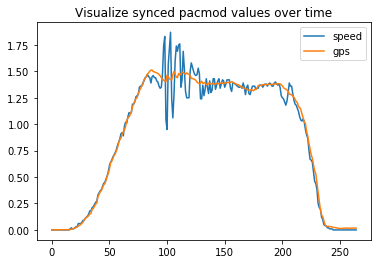

In [9]:
plt.plot(speed_vals, label="speed")
plt.plot(gps_speed, label="gps")
plt.title("Visualize synced pacmod values over time")
plt.legend()
plt.show()

In [20]:
gps_times_seconds = np.array([val[-1]*1e-9 for val in gps_vals])
delta_seconds = gps_times_seconds[1:]-gps_times_seconds[:-1]
total_distance = sum(delta_seconds * gps_speed[:-1])
total_distance_pacmod = sum(delta_seconds * speed_vals[:-1])
print(total_distance, total_distance_pacmod)

10.634607272230248 10.510788407325744


In [19]:
import utm
utm_data = utm.from_latlon(gps_vals[0,0], gps_vals[0,1])
east1, north1 = utm_data[0], utm_data[1]
utm_data = utm.from_latlon(gps_vals[-1,0], gps_vals[-1,1])
east2, north2 = utm_data[0], utm_data[1]
pose_total_dist = np.sqrt((east2-east1)**2 + (north2-north1)**2)
print(pose_total_dist)

10.528289981018476


In [ ]:
imgl_paths = [imgl_format_path.format(stamp) for stamp in df['image_stamp']]
img_vals = []
for i in imgl_paths:
    img = cv2.imread(i)
    img_vals.append(img)
    # cv2.imshow("res", img)
    # cv2.waitKey(5)
img_vals = np.array(img_vals)

In [ ]:
depth_paths = [depth_format_path.format(stamp) for stamp in df['depth_stamp']]
depth_vals = []
for path in depth_paths:
    depth_vals.append(np.load(path))
depth_vals = np.array(depth_vals)

All synced data arrays for this extracted rosbag

In [ ]:
print(gps_vals.shape)
print(speed_vals.shape)
print(steer_vals.shape)
print(accel_vals.shape)
print(brake_vals.shape)
print(depth_vals.shape)
print(img_vals.shape)